# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Hilal Tsabitul Azmi Arba'i | 5054251008 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [3]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, roc_auc_score, classification_report)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_style("whitegrid")
device = torch.device("cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cpu
Device: cpu


In [4]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv("/home/hilal/kuliah/ML/Modul-Praktikum-ML-RKA/8. Deep Learning/Churn_Modelling.csv")
display(df.head())

print("Jumlah baris dan kolom:", df.shape)
print()
df.info()
display(df.describe())
print("Jumlah missing value per kolom:")
print(df.isnull().sum())
print("\nJumlah data duplikat:", df.duplicated().sum())

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Jumlah baris dan kolom: (10000, 14)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


Jumlah missing value per kolom:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Jumlah data duplikat: 0


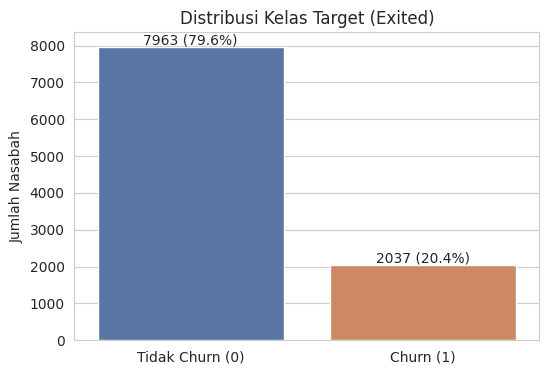

Exited
0    79.63
1    20.37
Name: proportion, dtype: float64
Rasio kelas 0 : kelas 1 = 3.91 : 1 -> dataset imbalanced


In [5]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

counts = df["Exited"].value_counts().sort_index()
ratio = df["Exited"].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=counts.index.map({0: "Tidak Churn (0)", 1: "Churn (1)"}), y=counts.values,
                 hue=counts.index, palette=["#4C72B0", "#DD8452"], legend=False)
for i, (c, r) in enumerate(zip(counts.values, ratio.values)):
    ax.text(i, c + 80, f"{c} ({r:.1f}%)", ha="center")
plt.title("Distribusi Kelas Target (Exited)")
plt.ylabel("Jumlah Nasabah")
plt.xlabel("")
plt.show()

print(ratio.round(2))
print(f"Rasio kelas 0 : kelas 1 = {counts[0] / counts[1]:.2f} : 1 -> dataset imbalanced")

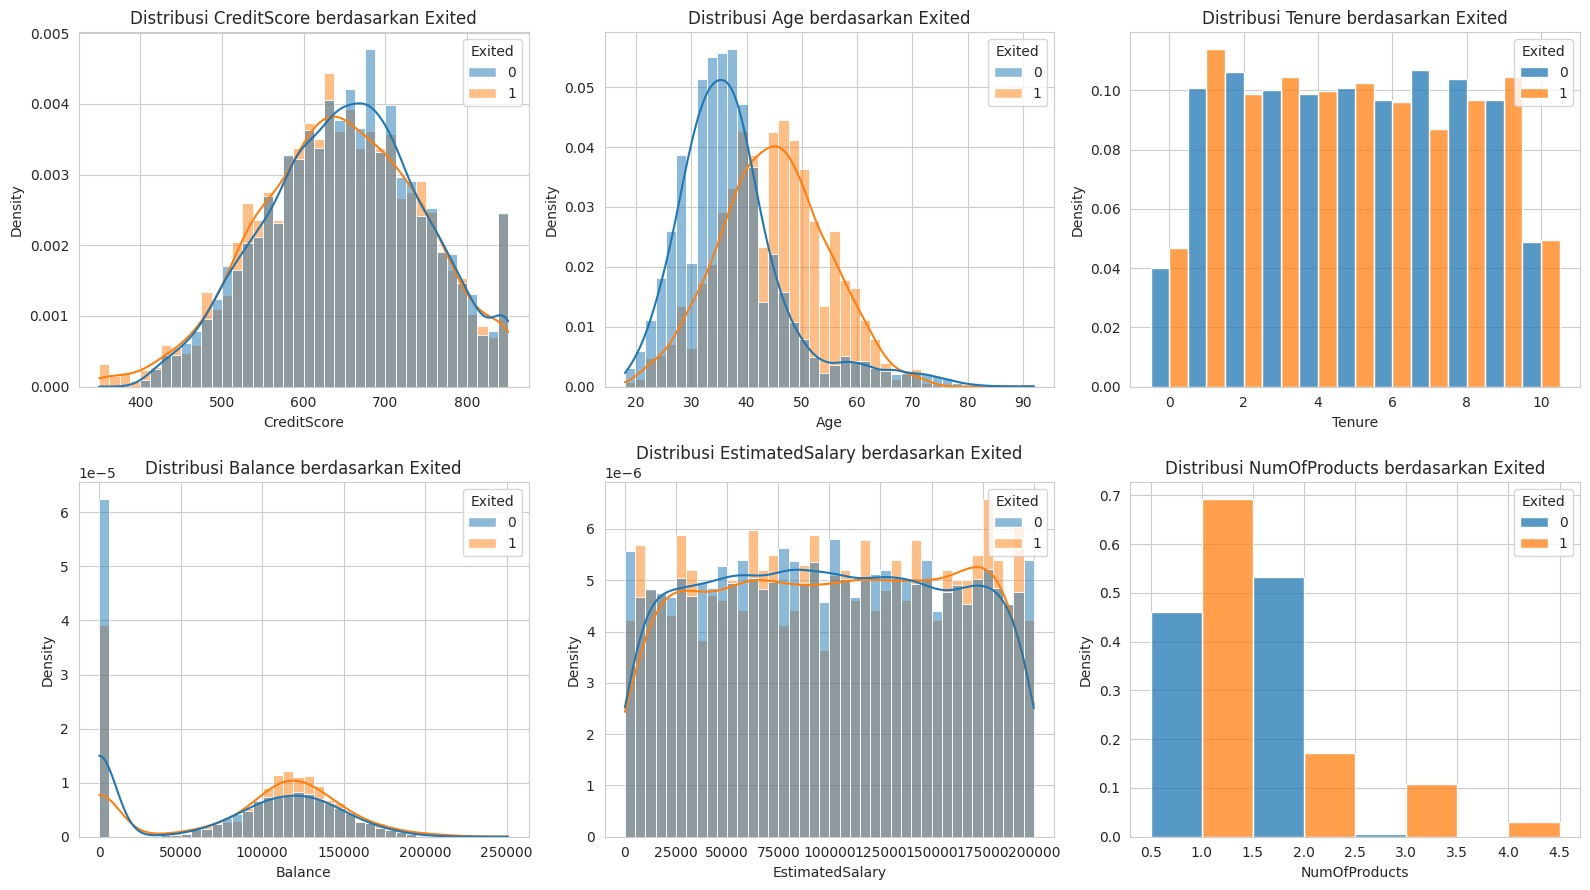

Exited,Tidak Churn,Churn
CreditScore,651.853196,645.351497
Age,37.408389,44.837997
Tenure,5.033279,4.932744
Balance,72745.296779,91108.539337
EstimatedSalary,99738.391772,101465.677531
NumOfProducts,1.544267,1.475209


In [6]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

num_features = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary", "NumOfProducts"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), num_features):
    if col in ["Tenure", "NumOfProducts"]:
        sns.histplot(data=df, x=col, hue="Exited", discrete=True, multiple="dodge",
                     stat="density", common_norm=False, ax=ax)
    else:
        sns.histplot(data=df, x=col, hue="Exited", kde=True, stat="density",
                     common_norm=False, bins=40, ax=ax)
    ax.set_title(f"Distribusi {col} berdasarkan Exited")
plt.tight_layout()
plt.show()

display(df.groupby("Exited")[num_features].mean().T.rename(columns={0: "Tidak Churn", 1: "Churn"}))

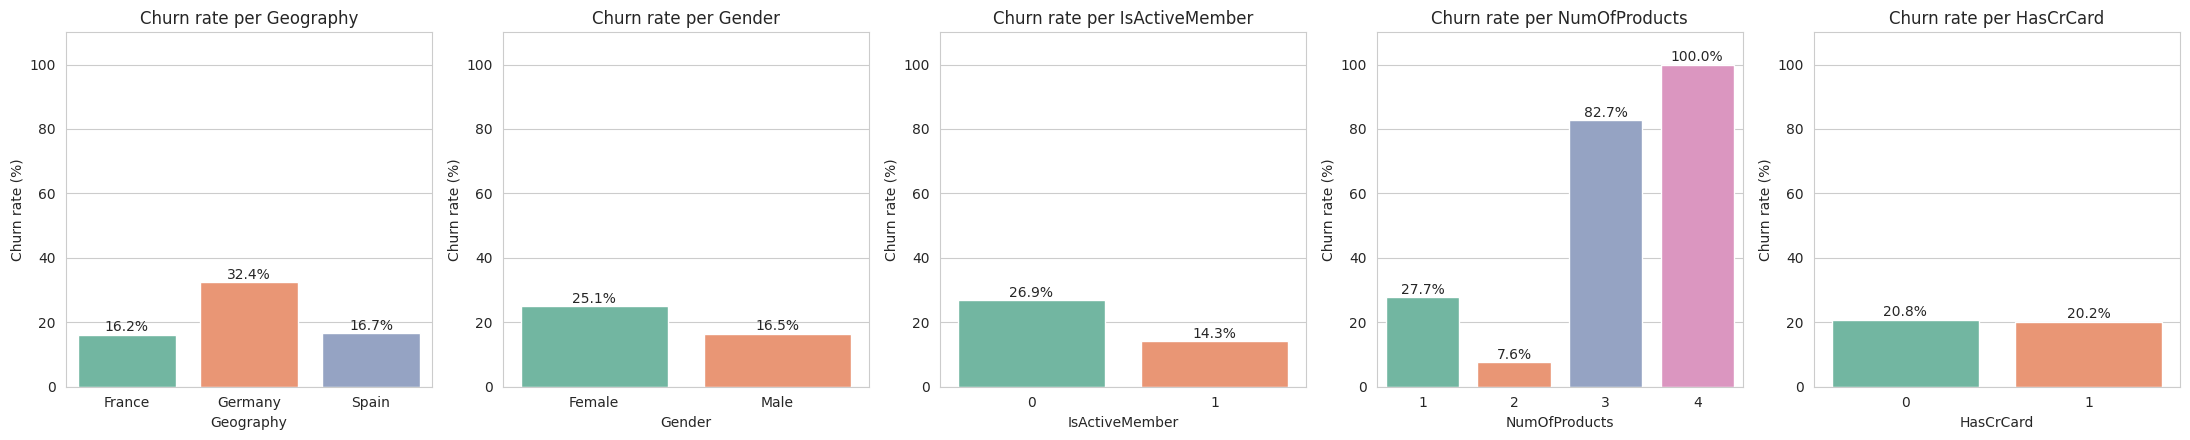

Exited     Tidak Churn (%)  Churn (%)
Geography                            
France               83.85      16.15
Germany              67.56      32.44
Spain                83.33      16.67 

Exited  Tidak Churn (%)  Churn (%)
Gender                            
Female            74.93      25.07
Male              83.54      16.46 

Exited          Tidak Churn (%)  Churn (%)
IsActiveMember                            
0                         73.15      26.85
1                         85.73      14.27 

Exited         Tidak Churn (%)  Churn (%)
NumOfProducts                            
1                        72.29      27.71
2                        92.42       7.58
3                        17.29      82.71
4                         0.00     100.00 

Exited     Tidak Churn (%)  Churn (%)
HasCrCard                            
0                    79.19      20.81
1                    79.82      20.18 



In [7]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

cat_features = ["Geography", "Gender", "IsActiveMember", "NumOfProducts", "HasCrCard"]

fig, axes = plt.subplots(1, len(cat_features), figsize=(22, 4.5))
for ax, col in zip(axes, cat_features):
    churn_rate = df.groupby(col)["Exited"].mean().mul(100)
    sns.barplot(x=churn_rate.index.astype(str), y=churn_rate.values, ax=ax,
                hue=churn_rate.index.astype(str), palette="Set2", legend=False)
    for i, v in enumerate(churn_rate.values):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center")
    ax.set_title(f"Churn rate per {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel(col)
    ax.set_ylim(0, 110)
plt.tight_layout()
plt.show()

for col in cat_features:
    print(pd.crosstab(df[col], df["Exited"], normalize="index").mul(100).round(2)
          .rename(columns={0: "Tidak Churn (%)", 1: "Churn (%)"}), "\n")

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

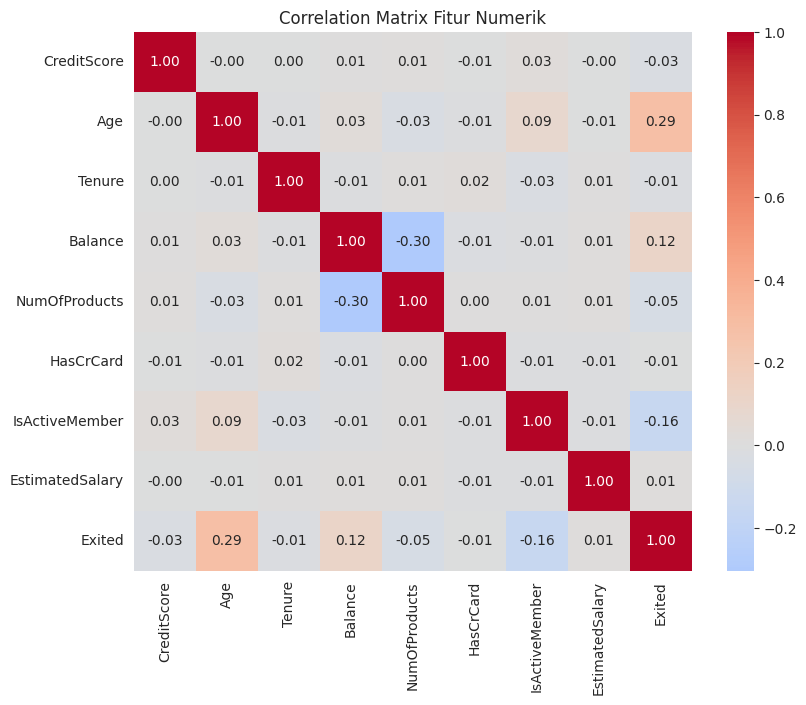

Korelasi setiap fitur terhadap Exited:
Age                0.285
IsActiveMember    -0.156
Balance            0.119
NumOfProducts     -0.048
CreditScore       -0.027
Tenure            -0.014
EstimatedSalary    0.012
HasCrCard         -0.007
Name: Exited, dtype: float64


In [8]:
# EDA tambahan 1: korelasi antar fitur numerik dan target
plt.figure(figsize=(9, 7))
corr = df.drop(columns=["RowNumber", "CustomerId", "Surname", "Geography", "Gender"]).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix Fitur Numerik")
plt.show()

print("Korelasi setiap fitur terhadap Exited:")
print(corr["Exited"].drop("Exited").sort_values(key=abs, ascending=False).round(3))

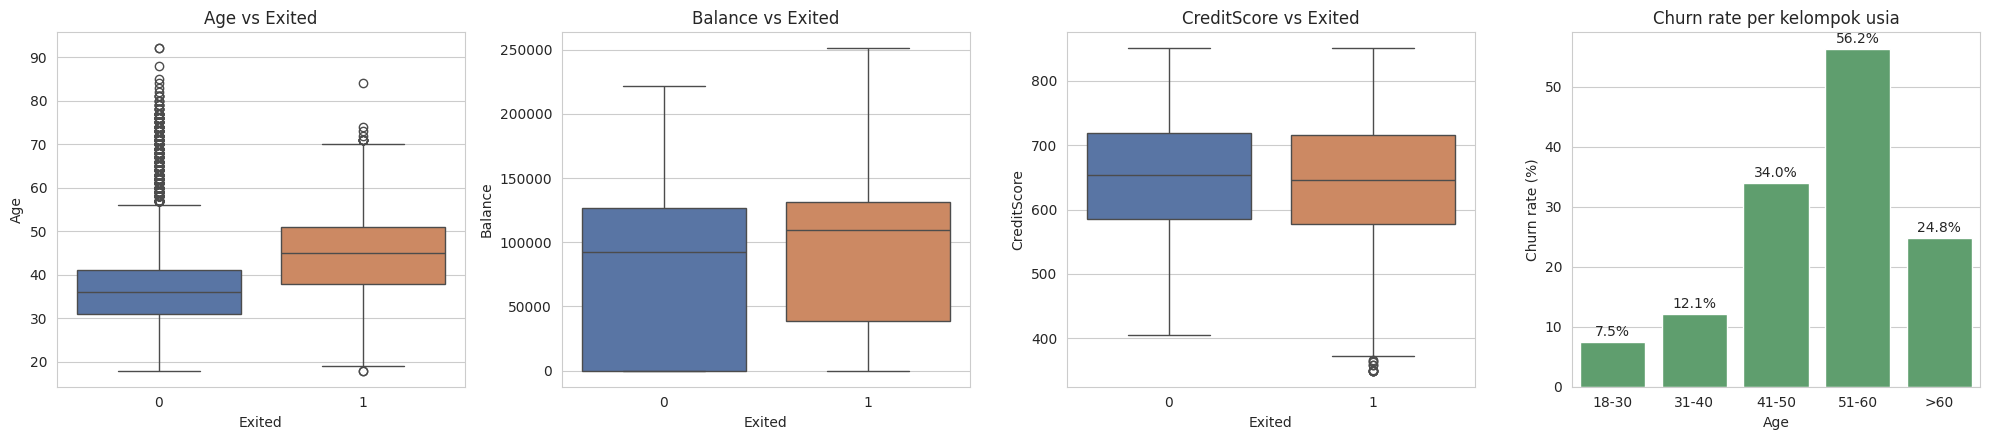

Nasabah dengan Balance = 0: 3617 (36.2%)
Churn rate Balance = 0 : 13.8%
Churn rate Balance > 0 : 24.1%


In [9]:
# EDA tambahan 2: boxplot fitur numerik utama terhadap Exited + churn rate per kelompok usia
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axes[:3], ["Age", "Balance", "CreditScore"]):
    sns.boxplot(data=df, x="Exited", y=col, hue="Exited", palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
    ax.set_title(f"{col} vs Exited")

age_group = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", ">60"])
rate = df.groupby(age_group, observed=True)["Exited"].mean().mul(100)
sns.barplot(x=rate.index.astype(str), y=rate.values, color="#55A868", ax=axes[3])
for i, v in enumerate(rate.values):
    axes[3].text(i, v + 1, f"{v:.1f}%", ha="center")
axes[3].set_title("Churn rate per kelompok usia")
axes[3].set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

# Proporsi nasabah dengan Balance = 0
zero_bal = (df["Balance"] == 0)
print(f"Nasabah dengan Balance = 0: {zero_bal.sum()} ({zero_bal.mean()*100:.1f}%)")
print(f"Churn rate Balance = 0 : {df.loc[zero_bal, 'Exited'].mean()*100:.1f}%")
print(f"Churn rate Balance > 0 : {df.loc[~zero_bal, 'Exited'].mean()*100:.1f}%")

**Insight dari EDA:**
- Dataset bersih: 10.000 baris, 14 kolom, **tidak ada missing value** maupun data duplikat.
- Target **imbalanced**: 79,63% tidak churn vs 20,37% churn (rasio ±3,9 : 1). Accuracy saja tidak cukup sebagai metrik, sehingga precision, recall, F1, dan ROC-AUC juga perlu dilihat.
- **Age** adalah fitur numerik paling berpengaruh (korelasi 0,285). Nasabah churn rata-rata lebih tua, dan churn rate naik tajam pada kelompok usia 41–60 tahun.
- **Geography**: churn rate di Germany (32,4%) sekitar dua kali lipat France (16,2%) dan Spain (16,7%).
- **Gender**: perempuan lebih sering churn (25,1%) dibanding laki-laki (16,5%).
- **IsActiveMember**: nasabah tidak aktif lebih banyak churn (26,9% vs 14,3%).
- **NumOfProducts** punya hubungan **non-linear**: 2 produk churn-nya paling rendah (7,6%), 1 produk 27,7%, sedangkan 3 dan 4 produk masing-masing 82,7% dan 100%. Korelasi linearnya hampir nol (-0,048) padahal fitur ini sangat informatif, jadi ada indikasi model non-linear (ANN) akan lebih unggul dari model linear.
- **Balance**: 36,2% nasabah memiliki saldo 0, dan churn rate mereka lebih rendah (13,8%) dibanding yang saldonya > 0 (24,1%).
- **HasCrCard, Tenure, EstimatedSalary, CreditScore** hampir tidak membedakan kelas churn (korelasi |r| < 0,03).

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [10]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# - RowNumber  : hanya nomor urut baris, tidak memiliki hubungan dengan perilaku nasabah.
# - CustomerId : ID unik nasabah, nilainya unik per baris sehingga tidak informatif
#                dan berisiko membuat model "menghafal" data.
# - Surname    : nama belakang nasabah, bersifat identitas (high cardinality) dan tidak relevan
#                secara logis dengan keputusan churn; memakainya juga berisiko menimbulkan bias.
df_model = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
print("Shape setelah drop:", df_model.shape)
df_model.head()

Shape setelah drop: (10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [11]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df_model.drop(columns=["Exited"])
y = df_model["Exited"].values

# 70% train, 30% sisanya dibagi rata menjadi validation (15%) dan test (15%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

for name, ys in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:<11}: {len(ys):>5} sampel | proporsi churn = {ys.mean()*100:.2f}%")

Train      :  7000 sampel | proporsi churn = 20.37%
Validation :  1500 sampel | proporsi churn = 20.40%
Test       :  1500 sampel | proporsi churn = 20.33%


In [12]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

nominal_cols = ["Geography"]
binary_cols = ["Gender"]
numeric_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                "HasCrCard", "IsActiveMember", "EstimatedSalary"]

preprocessor = ColumnTransformer(transformers=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"), nominal_cols),
    # drop="if_binary" -> Gender diubah menjadi satu kolom 0/1 (Male = 1, Female = 0)
    ("binary", OneHotEncoder(drop="if_binary"), binary_cols),
    ("scale", StandardScaler(), numeric_cols),
])

# fit hanya di train set, transform di train / val / test
X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print("Jumlah fitur setelah preprocessing:", X_train_p.shape[1])
print(list(feature_names))
pd.DataFrame(X_train_p, columns=feature_names).head()

Jumlah fitur setelah preprocessing: 12
['onehot__Geography_France', 'onehot__Geography_Germany', 'onehot__Geography_Spain', 'binary__Gender_Male', 'scale__CreditScore', 'scale__Age', 'scale__Tenure', 'scale__Balance', 'scale__NumOfProducts', 'scale__HasCrCard', 'scale__IsActiveMember', 'scale__EstimatedSalary']


,onehot__Geography_France,onehot__Geography_Germany,onehot__Geography_Spain,binary__Gender_Male,scale__CreditScore,scale__Age,scale__Tenure,scale__Balance,scale__NumOfProducts,scale__HasCrCard,scale__IsActiveMember,scale__EstimatedSalary
0,1.0,0.0,0.0,1.0,-0.575582,-1.796679,-0.349474,0.312906,-0.912483,0.643094,-1.034598,1.362512
1,0.0,0.0,1.0,0.0,0.398182,2.269825,-1.386929,-1.223574,0.799493,0.643094,0.966559,1.515472
2,1.0,0.0,0.0,1.0,1.693082,-0.756410,-1.386929,0.682321,-0.912483,0.643094,-1.034598,0.038955
3,1.0,0.0,0.0,1.0,0.740036,-1.796679,0.342162,-1.223574,0.799493,0.643094,-1.034598,1.671444
4,1.0,0.0,0.0,1.0,0.905783,-1.985818,-0.349474,-1.223574,0.799493,0.643094,0.966559,-0.899384


In [13]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

X_train_t = torch.tensor(X_train_p, dtype=torch.float32)
X_val_t = torch.tensor(X_val_p, dtype=torch.float32)
X_test_t = torch.tensor(X_test_p, dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

BATCH_SIZE = 64
train_dataset = TensorDataset(X_train_t, y_train_t)
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=g)

print("X_train:", X_train_t.shape, "| y_train:", y_train_t.shape)
print("X_val  :", X_val_t.shape, "| y_val  :", y_val_t.shape)
print("X_test :", X_test_t.shape, "| y_test :", y_test_t.shape)
print("Jumlah batch per epoch:", len(train_loader))

X_train: torch.Size([7000, 12]) | y_train: torch.Size([7000, 1])
X_val  : torch.Size([1500, 12]) | y_val  : torch.Size([1500, 1])
X_test : torch.Size([1500, 12]) | y_test : torch.Size([1500, 1])
Jumlah batch per epoch: 110


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [14]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

log_reg = LogisticRegression(max_iter=1000, random_state=SEED)
log_reg.fit(X_train_p, y_train)

y_proba_lr = log_reg.predict_proba(X_test_p)[:, 1]
y_pred_lr = (y_proba_lr >= 0.5).astype(int)

print("Accuracy Logistic Regression (test):", round(accuracy_score(y_test, y_pred_lr), 4))
print(classification_report(y_test, y_pred_lr, target_names=["Tidak Churn", "Churn"]))

Accuracy Logistic Regression (test): 0.8153
              precision    recall  f1-score   support

 Tidak Churn       0.83      0.97      0.89      1195
       Churn       0.65      0.20      0.31       305

    accuracy                           0.82      1500
   macro avg       0.74      0.59      0.60      1500
weighted avg       0.79      0.82      0.77      1500



## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [15]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

INPUT_DIM = X_train_t.shape[1]

class SimpleANN(nn.Module):
    def __init__(self, input_dim, hidden_dim=16):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),   # output berupa logit (tanpa Sigmoid)
        )

    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(SEED)
model_simple = SimpleANN(INPUT_DIM).to(device)
print(model_simple)
print("Jumlah parameter:", count_params(model_simple))

SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 225


In [16]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

def evaluate(model, X, y, criterion):
    """Hitung loss dan accuracy model pada suatu set data."""
    model.eval()
    with torch.no_grad():
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss = criterion(logits, y).item()
        preds = (torch.sigmoid(logits) >= 0.5).float()
        acc = (preds == y).float().mean().item()
    return loss, acc


def train_model(model, train_loader, X_train, y_train, X_val, y_val,
                criterion, optimizer, epochs=100, verbose_every=10):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)               # forward
            loss = criterion(logits, yb)     # hitung loss
            optimizer.zero_grad()
            loss.backward()                  # backpropagation
            optimizer.step()                 # update bobot

        tr_loss, tr_acc = evaluate(model, X_train, y_train, criterion)
        va_loss, va_acc = evaluate(model, X_val, y_val, criterion)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)

        if epoch == 1 or epoch % verbose_every == 0:
            print(f"Epoch {epoch:3d}/{epochs} | train_loss={tr_loss:.4f} train_acc={tr_acc:.4f} "
                  f"| val_loss={va_loss:.4f} val_acc={va_acc:.4f}")
    return history


LEARNING_RATE = 1e-3
EPOCHS = 100

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_simple.parameters(), lr=LEARNING_RATE)

history_simple = train_model(model_simple, train_loader, X_train_t, y_train_t, X_val_t, y_val_t,
                             criterion, optimizer, epochs=EPOCHS)

Epoch   1/100 | train_loss=0.4935 train_acc=0.7963 | val_loss=0.4924 val_acc=0.7960
Epoch  10/100 | train_loss=0.3678 train_acc=0.8496 | val_loss=0.3518 val_acc=0.8547
Epoch  20/100 | train_loss=0.3465 train_acc=0.8569 | val_loss=0.3293 val_acc=0.8620
Epoch  30/100 | train_loss=0.3430 train_acc=0.8591 | val_loss=0.3265 val_acc=0.8640
Epoch  40/100 | train_loss=0.3408 train_acc=0.8591 | val_loss=0.3254 val_acc=0.8653
Epoch  50/100 | train_loss=0.3393 train_acc=0.8626 | val_loss=0.3249 val_acc=0.8647
Epoch  60/100 | train_loss=0.3381 train_acc=0.8627 | val_loss=0.3252 val_acc=0.8647
Epoch  70/100 | train_loss=0.3374 train_acc=0.8640 | val_loss=0.3241 val_acc=0.8660
Epoch  80/100 | train_loss=0.3368 train_acc=0.8634 | val_loss=0.3255 val_acc=0.8640
Epoch  90/100 | train_loss=0.3364 train_acc=0.8644 | val_loss=0.3260 val_acc=0.8587
Epoch 100/100 | train_loss=0.3355 train_acc=0.8650 | val_loss=0.3257 val_acc=0.8653


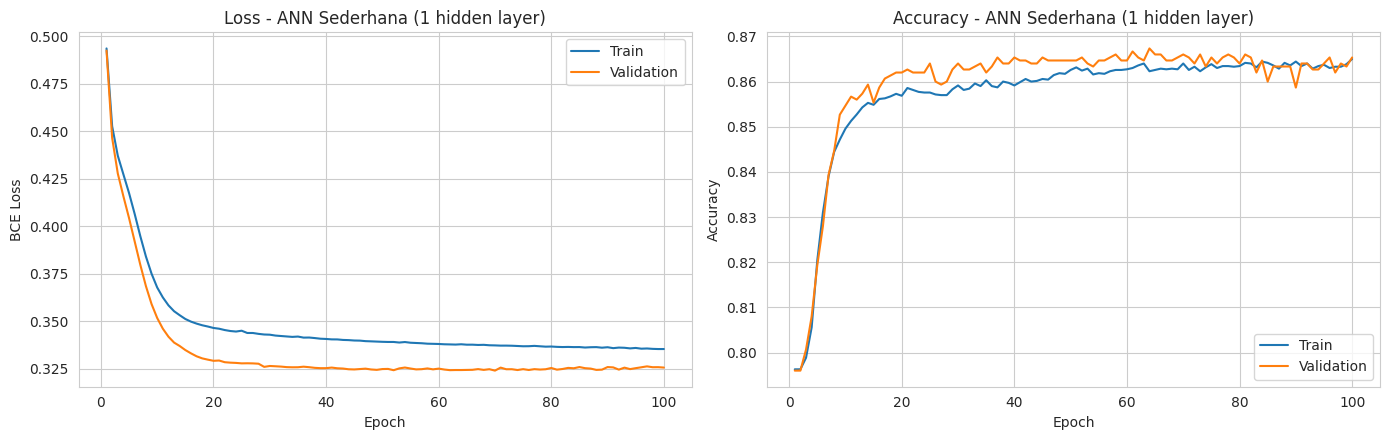

Val loss terendah = 0.3241 pada epoch 70 | final train_loss = 0.3355, final val_loss = 0.3257


In [17]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set_title(f"Loss - {title}")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss"); axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], label="Train")
    axes[1].plot(epochs, history["val_acc"], label="Validation")
    axes[1].set_title(f"Accuracy - {title}")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
    plt.tight_layout()
    plt.show()

    best = int(np.argmin(history["val_loss"]))
    print(f"Val loss terendah = {history['val_loss'][best]:.4f} pada epoch {best + 1} | "
          f"final train_loss = {history['train_loss'][-1]:.4f}, final val_loss = {history['val_loss'][-1]:.4f}")

plot_history(history_simple, "ANN Sederhana (1 hidden layer)")

In [18]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

def predict(model, X, threshold=0.5):
    model.eval()
    with torch.no_grad():
        logits = model(X.to(device))
        proba = torch.sigmoid(logits).cpu().numpy().ravel()
    pred = (proba >= threshold).astype(int)
    return proba, pred

y_proba_simple, y_pred_simple = predict(model_simple, X_test_t)
print("Accuracy ANN Sederhana (test):", round(accuracy_score(y_test, y_pred_simple), 4))
print(classification_report(y_test, y_pred_simple, target_names=["Tidak Churn", "Churn"]))

Accuracy ANN Sederhana (test): 0.8673
              precision    recall  f1-score   support

 Tidak Churn       0.88      0.97      0.92      1195
       Churn       0.79      0.48      0.59       305

    accuracy                           0.87      1500
   macro avg       0.83      0.72      0.76      1500
weighted avg       0.86      0.87      0.85      1500



## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [19]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class DeepANN(nn.Module):
    def __init__(self, input_dim, hidden_dims=(64, 32, 16), dropout=0.3):
        super().__init__()
        layers = []
        prev = input_dim
        for i, h in enumerate(hidden_dims):
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if i < len(hidden_dims) - 1:      # dropout di antara hidden layer
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))     # output logit
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

torch.manual_seed(SEED)
model_deep = DeepANN(INPUT_DIM).to(device)
print(model_deep)
print("Jumlah parameter:", count_params(model_deep))

DeepANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 3457


Epoch   1/100 | train_loss=0.4495 train_acc=0.7963 | val_loss=0.4397 val_acc=0.7960
Epoch  10/100 | train_loss=0.3447 train_acc=0.8579 | val_loss=0.3378 val_acc=0.8560
Epoch  20/100 | train_loss=0.3337 train_acc=0.8634 | val_loss=0.3281 val_acc=0.8627
Epoch  30/100 | train_loss=0.3273 train_acc=0.8667 | val_loss=0.3236 val_acc=0.8680
Epoch  40/100 | train_loss=0.3223 train_acc=0.8683 | val_loss=0.3244 val_acc=0.8680
Epoch  50/100 | train_loss=0.3203 train_acc=0.8687 | val_loss=0.3230 val_acc=0.8647
Epoch  60/100 | train_loss=0.3148 train_acc=0.8723 | val_loss=0.3223 val_acc=0.8667
Epoch  70/100 | train_loss=0.3116 train_acc=0.8714 | val_loss=0.3243 val_acc=0.8647
Epoch  80/100 | train_loss=0.3093 train_acc=0.8756 | val_loss=0.3270 val_acc=0.8667
Epoch  90/100 | train_loss=0.3058 train_acc=0.8763 | val_loss=0.3282 val_acc=0.8660
Epoch 100/100 | train_loss=0.3032 train_acc=0.8764 | val_loss=0.3270 val_acc=0.8640


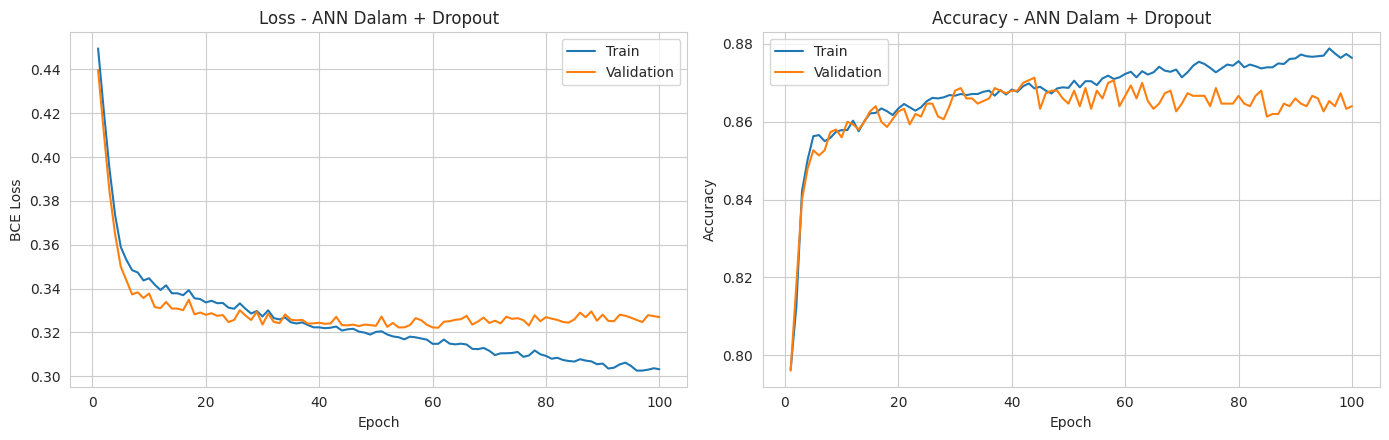

Val loss terendah = 0.3221 pada epoch 61 | final train_loss = 0.3032, final val_loss = 0.3270


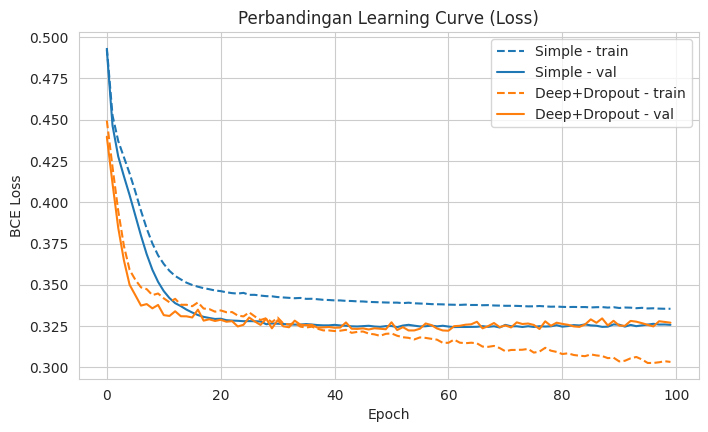

ANN Sederhana       : gap (val_loss - train_loss) di epoch terakhir = -0.0097
ANN Dalam + Dropout : gap (val_loss - train_loss) di epoch terakhir = 0.0238


In [20]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model_deep.parameters(), lr=LEARNING_RATE)

history_deep = train_model(model_deep, train_loader, X_train_t, y_train_t, X_val_t, y_val_t,
                           criterion, optimizer, epochs=EPOCHS)
plot_history(history_deep, "ANN Dalam + Dropout")

# Perbandingan learning curve kedua model
plt.figure(figsize=(8, 4.5))
plt.plot(history_simple["train_loss"], "--", color="C0", label="Simple - train")
plt.plot(history_simple["val_loss"], color="C0", label="Simple - val")
plt.plot(history_deep["train_loss"], "--", color="C1", label="Deep+Dropout - train")
plt.plot(history_deep["val_loss"], color="C1", label="Deep+Dropout - val")
plt.title("Perbandingan Learning Curve (Loss)")
plt.xlabel("Epoch"); plt.ylabel("BCE Loss"); plt.legend()
plt.show()

for name, h in [("ANN Sederhana", history_simple), ("ANN Dalam + Dropout", history_deep)]:
    gap = h["val_loss"][-1] - h["train_loss"][-1]
    print(f"{name:<20}: gap (val_loss - train_loss) di epoch terakhir = {gap:.4f}")

In [21]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

y_proba_deep, y_pred_deep = predict(model_deep, X_test_t)
print("Accuracy ANN Dalam + Dropout (test):", round(accuracy_score(y_test, y_pred_deep), 4))
print(classification_report(y_test, y_pred_deep, target_names=["Tidak Churn", "Churn"]))

Accuracy ANN Dalam + Dropout (test): 0.8633
              precision    recall  f1-score   support

 Tidak Churn       0.87      0.97      0.92      1195
       Churn       0.79      0.45      0.57       305

    accuracy                           0.86      1500
   macro avg       0.83      0.71      0.74      1500
weighted avg       0.86      0.86      0.85      1500



## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [22]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

# Pilih arsitektur terbaik berdasarkan val loss terendah dari 3.2 dan 3.3
best_simple = min(history_simple["val_loss"])
best_deep = min(history_deep["val_loss"])
use_deep = best_deep <= best_simple
print(f"Val loss terbaik -> Simple: {best_simple:.4f} | Deep+Dropout: {best_deep:.4f}")
print("Arsitektur yang dipakai:", "DeepANN (3.3)" if use_deep else "SimpleANN (3.2)")

torch.manual_seed(SEED)
model_weighted = (DeepANN(INPUT_DIM) if use_deep else SimpleANN(INPUT_DIM)).to(device)

n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
pos_weight = n_neg / n_pos
print(f"Kelas 0 = {n_neg}, kelas 1 = {n_pos} -> pos_weight = {pos_weight:.4f}")

criterion_weighted = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32, device=device))
optimizer = torch.optim.Adam(model_weighted.parameters(), lr=LEARNING_RATE)

history_weighted = train_model(model_weighted, train_loader, X_train_t, y_train_t, X_val_t, y_val_t,
                               criterion_weighted, optimizer, epochs=EPOCHS)

Val loss terbaik -> Simple: 0.3241 | Deep+Dropout: 0.3221
Arsitektur yang dipakai: DeepANN (3.3)
Kelas 0 = 5574, kelas 1 = 1426 -> pos_weight = 3.9088
Epoch   1/100 | train_loss=0.9399 train_acc=0.6619 | val_loss=0.9184 val_acc=0.6627
Epoch  10/100 | train_loss=0.7380 train_acc=0.7951 | val_loss=0.7227 val_acc=0.7927
Epoch  20/100 | train_loss=0.7176 train_acc=0.8114 | val_loss=0.7071 val_acc=0.8060
Epoch  30/100 | train_loss=0.7023 train_acc=0.7937 | val_loss=0.7010 val_acc=0.7847
Epoch  40/100 | train_loss=0.6922 train_acc=0.7901 | val_loss=0.7021 val_acc=0.7793
Epoch  50/100 | train_loss=0.6802 train_acc=0.8051 | val_loss=0.6933 val_acc=0.8027
Epoch  60/100 | train_loss=0.6738 train_acc=0.8099 | val_loss=0.6993 val_acc=0.8033
Epoch  70/100 | train_loss=0.6630 train_acc=0.8084 | val_loss=0.6984 val_acc=0.8040
Epoch  80/100 | train_loss=0.6551 train_acc=0.8113 | val_loss=0.6999 val_acc=0.8033
Epoch  90/100 | train_loss=0.6498 train_acc=0.7906 | val_loss=0.7119 val_acc=0.7733
Epoch 100

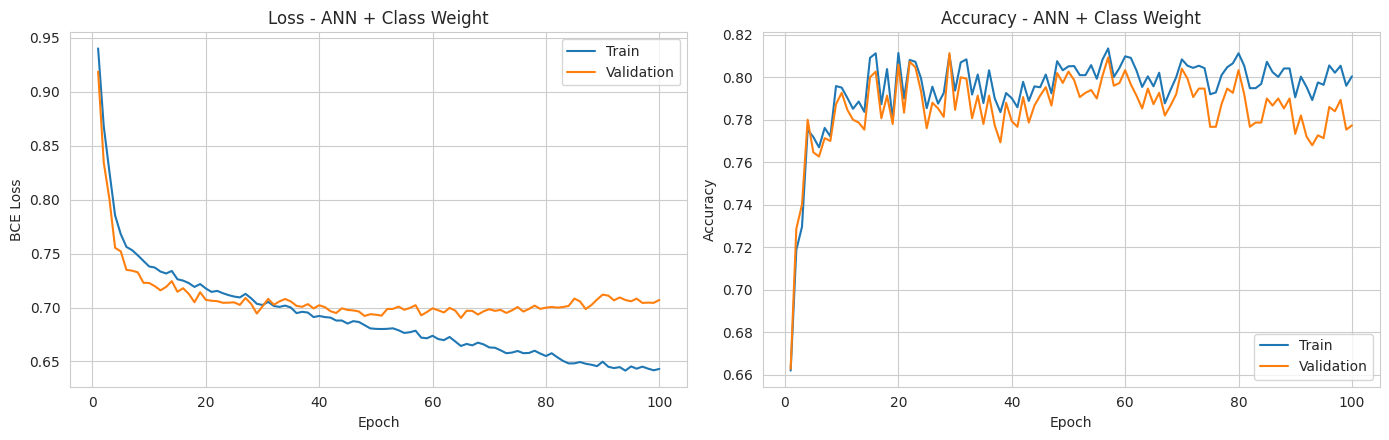

Val loss terendah = 0.6903 pada epoch 65 | final train_loss = 0.6431, final val_loss = 0.7070
Accuracy ANN + Class Weight (test): 0.772
              precision    recall  f1-score   support

 Tidak Churn       0.93      0.77      0.84      1195
       Churn       0.46      0.78      0.58       305

    accuracy                           0.77      1500
   macro avg       0.70      0.78      0.71      1500
weighted avg       0.84      0.77      0.79      1500



In [23]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

plot_history(history_weighted, "ANN + Class Weight")

y_proba_weighted, y_pred_weighted = predict(model_weighted, X_test_t)
print("Accuracy ANN + Class Weight (test):", round(accuracy_score(y_test, y_pred_weighted), 4))
print(classification_report(y_test, y_pred_weighted, target_names=["Tidak Churn", "Churn"]))

# 4. Evaluasi Model

In [24]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

results = {
    "Logistic Regression": (y_pred_lr, y_proba_lr),
    "ANN Sederhana": (y_pred_simple, y_proba_simple),
    "ANN Dalam + Dropout": (y_pred_deep, y_proba_deep),
    "ANN + Class Weight": (y_pred_weighted, y_proba_weighted),
}

rows = []
for name, (pred, proba) in results.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })
metrics_df = pd.DataFrame(rows).set_index("Model").round(4)
print(metrics_df.to_string())
display(metrics_df.style.highlight_max(axis=0, color="lightgreen").format("{:.4f}"))

                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                              
Logistic Regression    0.8153     0.6458  0.2033    0.3092   0.7912
ANN Sederhana          0.8673     0.7880  0.4754    0.5930   0.8616
ANN Dalam + Dropout    0.8633     0.7907  0.4459    0.5702   0.8643
ANN + Class Weight     0.7720     0.4641  0.7836    0.5829   0.8578


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092,0.7912
ANN Sederhana,0.8673,0.7880,0.4754,0.5930,0.8616
ANN Dalam + Dropout,0.8633,0.7907,0.4459,0.5702,0.8643
ANN + Class Weight,0.7720,0.4641,0.7836,0.5829,0.8578


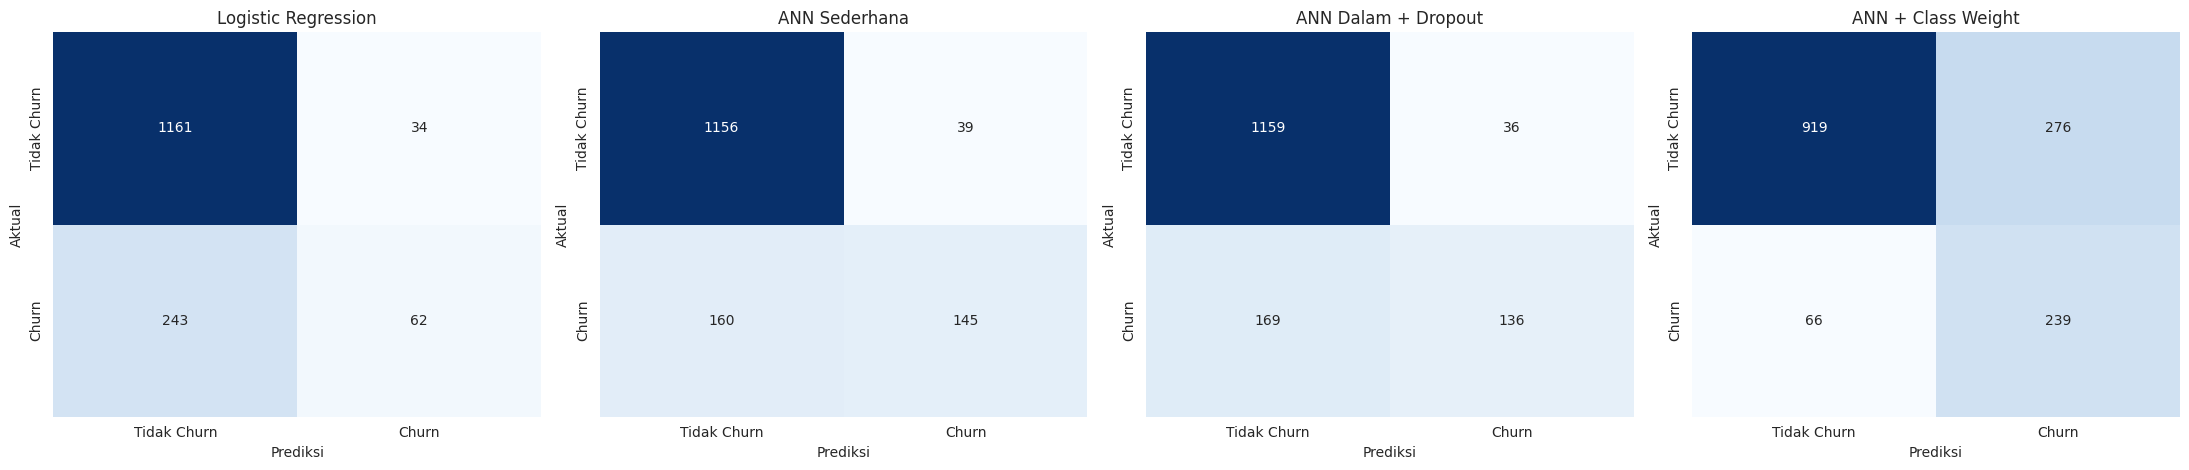

Logistic Regression  [1161   34  243   62] (TN, FP, FN, TP)
ANN Sederhana        [1156   39  160  145] (TN, FP, FN, TP)
ANN Dalam + Dropout  [1159   36  169  136] (TN, FP, FN, TP)
ANN + Class Weight   [919 276  66 239] (TN, FP, FN, TP)


In [25]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, axes = plt.subplots(1, len(results), figsize=(22, 4.8))
for ax, (name, (pred, _)) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Tidak Churn", "Churn"], yticklabels=["Tidak Churn", "Churn"])
    ax.set_title(name)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()

for name, (pred, _) in results.items():
    print(f"{name:<20}", confusion_matrix(y_test, pred).ravel(), "(TN, FP, FN, TP)")

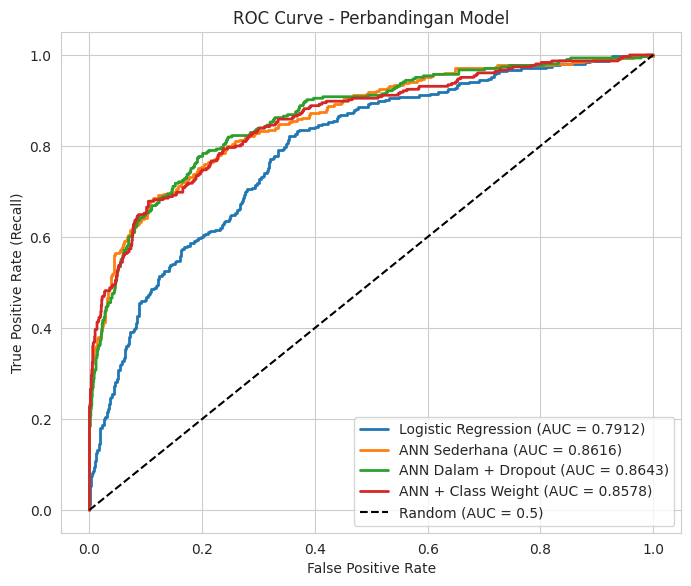

In [26]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(8, 6.5))
for name, (_, proba) in results.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Perbandingan Model")
plt.legend(loc="lower right")
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

**Tabel ringkasan hasil pada test set (1.500 sampel, 305 churn):**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0,8153 | 0,6458 | 0,2033 | 0,3092 | 0,7912 |
| ANN Sederhana (16) | **0,8673** | 0,7880 | 0,4754 | **0,5930** | 0,8616 |
| ANN Dalam + Dropout (64-32-16) | 0,8633 | **0,7907** | 0,4459 | 0,5702 | **0,8643** |
| ANN + Class Weight | 0,7720 | 0,4641 | **0,7836** | 0,5829 | 0,8578 |

**1. Logistic Regression vs ANN**

Logistic Regression memiliki accuracy 81,5%, hanya sedikit di atas tebakan "semua tidak churn" (79,7%). Recall kelas churn-nya cuma 20,3%: dari 305 nasabah churn, hanya 62 yang terdeteksi (243 False Negative). ROC-AUC-nya 0,79. Penyebabnya, model linear tidak bisa menangkap pola non-linear yang terlihat di EDA, misalnya NumOfProducts (churn rendah di 2 produk tetapi sangat tinggi di 3–4 produk) dan efek Age yang memuncak di usia paruh baya.

Semua ANN jauh lebih baik. ANN sederhana dengan hanya 225 parameter menaikkan accuracy menjadi 86,7%, recall churn menjadi 47,5% (145 TP), F1 dari 0,31 menjadi 0,59, dan ROC-AUC dari 0,79 menjadi 0,86. Artinya hidden layer dengan aktivasi ReLU cukup untuk memodelkan interaksi dan non-linearitas antar fitur.

**2. Learning curve dan overfitting/underfitting**

- **ANN Sederhana**: train loss dan val loss turun bersama lalu mendatar di sekitar epoch 30–40 (val loss minimum 0,3241 di epoch 70). Di epoch terakhir val loss (0,3257) bahkan sedikit di bawah train loss (0,3355), sehingga **tidak ada tanda overfitting**. Model dengan kapasitas kecil ini sudah mencapai *good fit*. Loss yang masih sekitar 0,33 menunjukkan batas informasi dari fitur yang tersedia, bukan underfitting yang parah.
- **ANN Dalam + Dropout**: konvergensinya lebih cepat (val loss 0,3378 di epoch 10 vs 0,3518 pada model sederhana) dan mencapai val loss minimum lebih rendah (0,3221 di epoch 61). Namun setelah epoch ±60, train loss terus turun (sampai 0,3032) sedangkan val loss naik kembali ke 0,3270, dan gap val–train membesar menjadi +0,024. Ini **tanda awal overfitting ringan**: kapasitas model (3.457 parameter, ±15× model sederhana) cukup besar untuk mulai menghafal data latih meskipun sudah memakai Dropout 0,3.
- **ANN + Class Weight**: nilai loss-nya lebih besar (±0,65–0,70) karena loss diberi bobot, sehingga tidak bisa dibandingkan langsung dengan model lain. Polanya mirip model dalam: val loss minimum di epoch 65, lalu naik lagi sementara train loss terus turun (overfitting ringan). Kurva accuracy validasinya juga lebih fluktuatif (77–81%) karena model kini lebih "berani" memprediksi churn, sehingga accuracy lebih sensitif terhadap pergeseran decision boundary.

**3. Pengaruh penambahan layer dan Dropout**

Menambah layer (64-32-16) dan Dropout **tidak memberikan peningkatan berarti** pada test set. ROC-AUC sedikit naik (0,8616 → 0,8643) dan precision hampir sama (0,79), tetapi accuracy (0,8673 → 0,8633), recall (0,475 → 0,446), dan F1 (0,593 → 0,570) sedikit turun. Selisih sekecil ini (±0,3–3 poin) masih dalam rentang variasi akibat random seed. Untuk data tabular berukuran kecil-menengah dengan 12 fitur, model yang lebih dalam tidak otomatis lebih baik. Dropout memang menahan overfitting sehingga gap train–val tetap kecil (0,024), tetapi karena dilatih tanpa early stopping selama 100 epoch, model tetap mulai overfit setelah titik optimalnya. Dengan kata lain, Dropout memperlambat overfitting, tetapi tidak menghilangkannya.

**4. Pengaruh class weight terhadap precision dan recall**

Dengan `pos_weight = 5574/1426 ≈ 3,91`, kesalahan pada kelas churn dihukum ±3,9× lebih berat. Hasilnya terlihat jelas pada confusion matrix:
- **Recall churn naik drastis** dari 44,6% menjadi **78,4%**. True Positive naik dari 136 menjadi 239, dan False Negative turun dari 169 menjadi 66.
- Sebagai gantinya, **precision turun** dari 79,1% menjadi 46,4%. False Positive naik dari 36 menjadi 276, dan accuracy turun ke 77,2%.
- F1 relatif stabil (0,57 → 0,58) dan ROC-AUC hampir sama (0,864 → 0,858). Artinya kemampuan model **membedakan** kelas (ranking probabilitas) tidak banyak berubah. Yang bergeser hanya **titik operasi (threshold efektif)** model ke arah yang lebih sensitif terhadap kelas churn.

Ini adalah trade-off precision–recall yang klasik. Dalam konteks bisnis churn, kehilangan nasabah (False Negative) biasanya jauh lebih mahal daripada memberi promo retensi kepada nasabah yang sebenarnya tidak akan churn (False Positive). Karena itu, model dengan class weight lebih berguna secara praktis walaupun accuracy-nya paling rendah. Hasil ini juga menegaskan bahwa **accuracy menyesatkan pada data imbalanced**: model dengan accuracy tertinggi (ANN Sederhana) justru melewatkan lebih dari separuh nasabah yang churn.

**5. ROC Curve**

Kurva ROC ketiga ANN hampir berimpit (AUC 0,858–0,864) dan semuanya berada jelas di atas Logistic Regression (AUC 0,791). Jadi peningkatan terbesar berasal dari penggunaan model non-linear (ANN), bukan dari kedalaman arsitektur maupun class weight. Class weight hanya memilih titik yang berbeda di kurva ROC yang hampir sama.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

**Kesimpulan**
1. Dataset Churn Modelling bersih (tanpa missing value) tetapi imbalanced (20,4% churn). Fitur paling berpengaruh adalah Age, NumOfProducts (non-linear), IsActiveMember, Geography (Germany), Gender, dan Balance.
2. Seluruh model ANN jauh mengungguli baseline Logistic Regression. ROC-AUC naik dari 0,79 menjadi ±0,86 dan F1 kelas churn dari 0,31 menjadi ±0,58. Ini menunjukkan pentingnya kemampuan non-linear untuk data ini.
3. ANN sederhana (1 hidden layer, 16 neuron, 225 parameter) sudah memberi accuracy dan F1 terbaik (0,867 / 0,593) tanpa overfitting. ANN yang lebih dalam dengan Dropout hanya sedikit menaikkan ROC-AUC (0,864), tetapi mulai overfit setelah ±60 epoch. Pada kasus ini, menambah kompleksitas tidak sebanding dengan hasilnya.
4. Class weight (`pos_weight ≈ 3,91`) sangat efektif menaikkan recall churn (44,6% → 78,4%) dengan konsekuensi precision turun (79,1% → 46,4%) dan accuracy turun ke 77,2%. Untuk kebutuhan bisnis yang fokus menangkap sebanyak mungkin nasabah yang akan churn, **ANN + Class Weight adalah model yang paling direkomendasikan**. Jika biaya False Positive tinggi, ANN Sederhana lebih cocok.

**Saran**
1. **Early stopping** berdasarkan val loss (dengan menyimpan bobot terbaik) agar model dalam dan model class weight berhenti di titik optimal (±epoch 60–65) dan tidak overfit.
2. **Threshold tuning**: daripada threshold tetap 0,5, pilih threshold berdasarkan kurva precision-recall pada validation set sesuai biaya bisnis FN vs FP. Karena AUC ketiga ANN hampir sama, threshold tuning pada ANN biasa bisa memberi efek yang mirip class weight.
3. **Hyperparameter tuning** (jumlah neuron/layer, dropout rate, learning rate, batch size, weight decay/L2) menggunakan validation set atau k-fold cross validation, serta menjalankan beberapa random seed agar perbedaan antar model bisa diuji signifikansinya.
4. Mencoba **teknik imbalanced lain** seperti oversampling (SMOTE), undersampling, atau focal loss sebagai pembanding class weight.
5. **Feature engineering**, misalnya flag `Balance == 0`, rasio Balance/EstimatedSalary, kelompok usia, atau menjadikan NumOfProducts sebagai fitur kategorikal (one-hot) agar pola non-linearnya lebih mudah dipelajari.
6. Membandingkan dengan model berbasis pohon (Random Forest, XGBoost, LightGBM) yang umumnya sangat kuat untuk data tabular, serta menambahkan BatchNorm atau learning rate scheduler pada ANN.